# 🚀 Модуль 7. Урок 3. Оценка метрик: пропорции (Z-тест) vs непрерывные метрики (ARPU / Bootstrap)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_07_ab_testing/lesson_03_evaluating_metrics_proportions_means.ipynb)

## 📌 Бизнес-контекст и методология
Метрики бывают двух принципиально разных типов:
1. **Бинарные (пропорции):** Конверсия в клик (CTR), конверсия в покупку (CR), отток. Анализируются через двухвыборочный Z-тест пропорций.
2. **Непрерывные (со скошенным распределением):** ARPU, средний чек, LTV. Анализируются через Бутстрап (Bootstrap) или линеаризацию.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

ab_csv = ensure_dataset("ab_test_checkout.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Сравним конверсию двух вариантов чекаута через двухвыборочный Z-тест пропорций и оценим бутстрапом разницу в выручке на пользователя.

In [2]:
from scipy import stats
import pandas as pd
import numpy as np

df_ab = pd.read_csv(ab_csv)

conv_a = df_ab[df_ab['test_group'] == 'A_Control']['converted'].sum()
n_a = len(df_ab[df_ab['test_group'] == 'A_Control'])
conv_b = df_ab[df_ab['test_group'] == 'B_Variant']['converted'].sum()
n_b = len(df_ab[df_ab['test_group'] == 'B_Variant'])

cr_a = conv_a / n_a
cr_b = conv_b / n_b

p_pool = (conv_a + conv_b) / (n_a + n_b)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
z_stat = (cr_b - cr_a) / se_pool
p_val_cr = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print(f"Конверсия A (Control):   {cr_a:.2%}")
print(f"Конверсия B (Treatment): {cr_b:.2%}")
print(f"Абсолютный прирост:      {(cr_b - cr_a)*100:+.2f} п.п. (p-value: {p_val_cr:.4f})")

Конверсия A (Control):   8.50%
Конверсия B (Treatment): 9.26%
Абсолютный прирост:      +0.76 п.п. (p-value: 0.1816)


### 📊 Визуализация: Доверительные интервалы конверсии и Бутстрап ARPU
Графики ниже показывают доверительные интервалы для конверсий и бутстрап-распределение разницы средней выручки на пользователя.

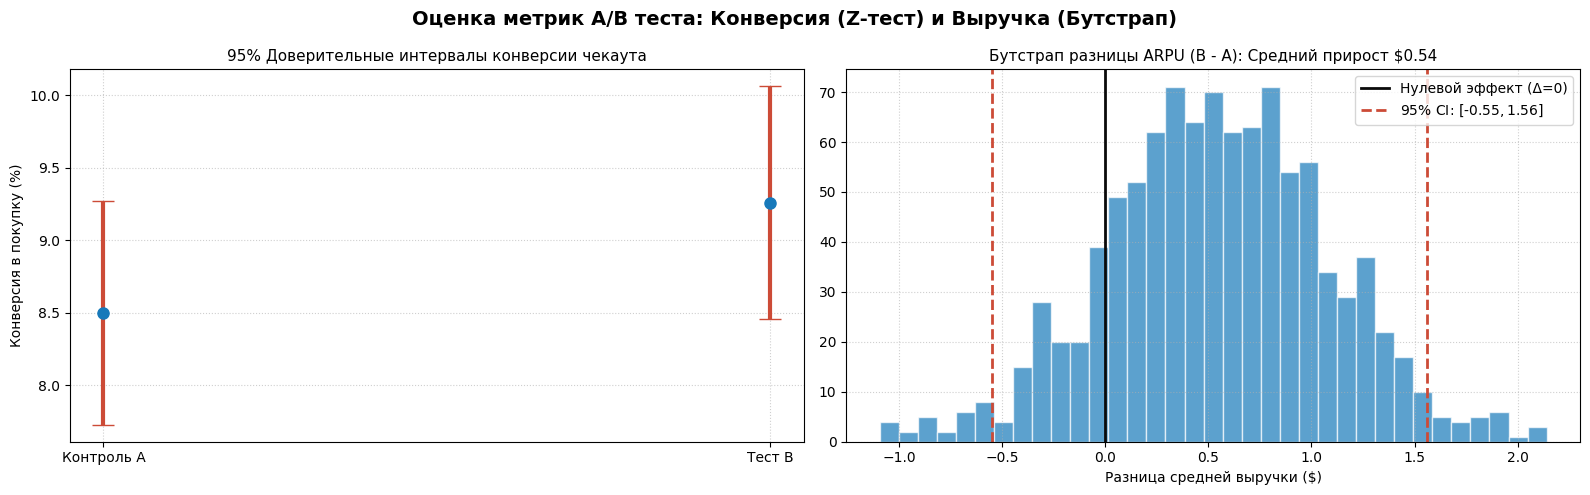

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Оценка метрик A/B теста: Конверсия (Z-тест) и Выручка (Бутстрап)', fontsize=14, fontweight='bold')

# 1. Доверительные интервалы конверсий
ax1 = axes[0]
se_a = np.sqrt(cr_a * (1 - cr_a) / n_a)
se_b = np.sqrt(cr_b * (1 - cr_b) / n_b)

ci_a = (cr_a - 1.96 * se_a, cr_a + 1.96 * se_a)
ci_b = (cr_b - 1.96 * se_b, cr_b + 1.96 * se_b)

ax1.errorbar(['Контроль A', 'Тест B'], [cr_a * 100, cr_b * 100],
             yerr=[[ (cr_a - ci_a[0])*100, (cr_b - ci_b[0])*100 ],
                   [ (ci_a[1] - cr_a)*100, (ci_b[1] - cr_b)*100 ]],
             fmt='o', color='#1779ba', ecolor='#cc4b37', elinewidth=3, capsize=8, markersize=8)

ax1.set_title('95% Доверительные интервалы конверсии чекаута', fontsize=11)
ax1.set_ylabel('Конверсия в покупку (%)')
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Бутстрап разницы ARPU (1000 итераций)
ax2 = axes[1]
rev_a = df_ab[df_ab['test_group'] == 'A_Control']['revenue'].values
rev_b = df_ab[df_ab['test_group'] == 'B_Variant']['revenue'].values

np.random.seed(42)
boot_diffs = []
for _ in range(1000):
    sample_a = np.random.choice(rev_a, size=len(rev_a), replace=True)
    sample_b = np.random.choice(rev_b, size=len(rev_b), replace=True)
    boot_diffs.append(np.mean(sample_b) - np.mean(sample_a))

boot_diffs = np.array(boot_diffs)
ci_boot = np.percentile(boot_diffs, [2.5, 97.5])

ax2.hist(boot_diffs, bins=35, color='#1779ba', alpha=0.7, edgecolor='white')
ax2.axvline(0, color='#0a0a0a', linestyle='-', linewidth=2, label='Нулевой эффект (Δ=0)')
ax2.axvline(ci_boot[0], color='#cc4b37', linestyle='--', linewidth=2, label=f'95% CI: [{ci_boot[0]:.2f}$, {ci_boot[1]:.2f}$]')
ax2.axvline(ci_boot[1], color='#cc4b37', linestyle='--', linewidth=2)
ax2.set_title(f'Бутстрап разницы ARPU (B - A): Средний прирост ${np.mean(boot_diffs):.2f}', fontsize=11)
ax2.set_xlabel('Разница средней выручки ($)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Доля положительных бутстрап-итераций
Посчитайте процент итераций бутстрапа, в которых выручка варианта B превысила вариант A (`boot_diffs > 0`).

In [4]:
### ВАШ КОД ЗДЕСЬ
p_b_wins = np.mean(boot_diffs > 0)

print(f"Вероятность превосходства варианта B: {p_b_wins:.1%}")
assert 0.0 <= p_b_wins <= 1.0, "Вероятность обязана лежать в интервале [0, 1]"
print("✅ Тест успешно пройден!")

Вероятность превосходства варианта B: 85.5%
✅ Тест успешно пройден!


### 💼 Когда бутстрап превосходит t-тест?
Выручка в e-commerce содержит 90% нулей (не купили) и единичные чеки на $500+. Обычный t-тест на таких данных теряет калибровку. Бутстрап не требует никаких предположений о нормальности данных.